In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# EU cohesion payments, and Germany and Belgium in the "why the South" family
Two loose ends of notebook 34 are closed here. **(1) EU funds by region.** The notebook asked what sets the South apart; one candidate is the support it received. The Commission's regionalised payment data (`sources/eu_payments.py`: ERDF, Cohesion Fund and ESF payments of the 2007-2013 programme mapped to NUTS2, translated to NUTS 2021) give, for the regions of every member state, the cumulative support **per inhabitant** and **as a share of regional GDP** over the programme years. OpenCoesione (Italy's project files, with national co-financing and the 2014-2020 cycle) was not used: it needs project files of hundreds of megabytes and covers Italy only. **(2) Germany and Belgium in the EQI family.** The quality-of-government index exists only at NUTS1 for the two countries (16 Laender, 3 regions), so notebook 34 left them out; here their outcomes are aggregated from NUTS2 to NUTS1 (sums for extensive indicators, population-weighted means for rates, `analysis/nuts1.py`) and the EQI family is rerun with them.

**Design, funds.** Predictors: cohesion payments per inhabitant and as % of GDP. Outcomes: the change between the 2005-07 window mean and the 2015-19 one of log GDP per head (PPS), the employment rate, the unemployment rate, GDP per hour and hours per inhabitant. Everything is demeaned by country and purged of the initial log income (funds go to poorer regions: the question is whether, among regions of one country with the same starting income, those with more support moved differently). Spearman with the within-country permutation p, BH over the ten tests (two predictors times five outcomes), leave-one-country-out, spatial filtering of every column, Italy's slope against the other countries' (placebo ranking), a shuffled null, and variants (all funds with the EAFRD, the pre-2004 member states only, no income control, a 2005-09 baseline).

**Design, Germany and Belgium.** The EQI family of notebook 34 (the composite and its three components against the six regional gaps, four waves, plain and beyond income) without and with the two countries at NUTS1. They enter only at NUTS1 (their NUTS2 rows are dropped) and only through the EQI predictors: the structural business statistics do not exist at NUTS1 in the project, so pairs with those predictors lose the two countries and are left out of the comparison. Spatial filtering is not applied (it needs NUTS1 boundaries). Descriptive associations only: funds go where regions are poor for reasons that also drive their outcomes.

regions with cohesion payments in the 2007-2013 programme and population/GDP data: 224 | countries: 25
median cohesion payments per inhabitant (EUR, cumulative) and % of GDP by country, top 8:


country,HU,CZ,EE,PT,EL,LV,SK,MT
funds_cohesion_per_head,2720.3,2582.7,2554.8,2228.3,2206.6,2138.8,2068.0,2033.2
funds_cohesion_pct_gdp,5.6,2.8,2.9,2.2,2.3,3.2,2.6,1.8


Italian regions (EUR per inhabitant; % of GDP):


geo,ITF6,ITG1,ITF4,ITF3,ITF5,ITG2,ITC2,ITF2,ITI2,ITC3,...,ITF1,ITI1,ITH4,ITH2,ITI3,ITI4,ITH1,ITH3,ITH5,ITC4
funds_cohesion_per_head,1542.6,1260.3,1215.9,1042.3,898.3,596.9,408.4,365.9,282.7,199.2,...,182.6,177.1,158.4,152.1,146.9,135.2,121.8,115.1,106.1,57.4
funds_cohesion_pct_gdp,1.3,1.0,1.0,0.8,0.7,0.4,0.2,0.2,0.2,0.1,...,0.1,0.1,0.1,0.1,0.1,0.1,0.0,0.1,0.0,0.0


PRIMARY family (within country, beyond initial income; within-country permutation p; BH over the ten tests):


,x,y,n,rho,p,q_value,loo_min_abs_rho,loo_sign_flips
0,funds_cohesion_per_head,ln_gdp_pc,190,0.114,0.116,0.239,0.048,0
1,funds_cohesion_per_head,employment_rate_20_64,202,0.118,0.120,0.239,0.033,0
2,funds_cohesion_per_head,unemployment_rate,200,-0.147,0.050,0.165,0.034,0
3,funds_cohesion_per_head,gdp_per_hour_eur,174,0.050,0.493,0.617,0.006,1
4,funds_cohesion_per_head,hours_per_inhabitant,173,0.193,0.013,0.072,0.152,0
5,funds_cohesion_pct_gdp,ln_gdp_pc,195,0.015,0.832,0.832,0.002,3
6,funds_cohesion_pct_gdp,employment_rate_20_64,207,0.083,0.259,0.431,0.040,0
7,funds_cohesion_pct_gdp,unemployment_rate,205,-0.058,0.421,0.602,0.026,0
8,funds_cohesion_pct_gdp,gdp_per_hour_eur,179,0.016,0.823,0.832,0.003,2
9,funds_cohesion_pct_gdp,hours_per_inhabitant,173,0.199,0.014,0.072,0.161,0


... (3 outputs left out)

,variant,x,y,n,rho,p,q_value
0,all funds (with the EAFRD),funds_all_per_head,ln_gdp_pc,190,0.141,0.053,0.134
1,all funds (with the EAFRD),funds_all_per_head,employment_rate_20_64,202,0.106,0.169,0.212
2,all funds (with the EAFRD),funds_all_per_head,unemployment_rate,200,-0.122,0.113,0.189
3,all funds (with the EAFRD),funds_all_per_head,gdp_per_hour_eur,174,0.063,0.398,0.398
4,all funds (with the EAFRD),funds_all_per_head,hours_per_inhabitant,173,0.166,0.035,0.134
5,pre-2004 member states only,funds_cohesion_per_head,ln_gdp_pc,156,0.112,0.152,0.253
6,pre-2004 member states only,funds_cohesion_per_head,employment_rate_20_64,168,0.177,0.025,0.095
7,pre-2004 member states only,funds_cohesion_per_head,unemployment_rate,166,-0.183,0.026,0.095
8,pre-2004 member states only,funds_cohesion_per_head,gdp_per_hour_eur,140,0.076,0.349,0.383
9,pre-2004 member states only,funds_cohesion_per_head,hours_per_inhabitant,139,0.177,0.045,0.114


Italy's slope against the other countries' (p_rank = share of countries at least as far from the others; plain and filtered):


,x,y,n_countries,slope_diff,p_rank,p_rank_filtered
0,funds_cohesion_per_head,ln_gdp_pc,14,-0.000,0.929,1.000
1,funds_cohesion_per_head,employment_rate_20_64,15,-0.004,0.133,0.333
2,funds_cohesion_per_head,unemployment_rate,14,0.004,0.143,0.071
3,funds_cohesion_per_head,gdp_per_hour_eur,15,0.001,0.600,0.333
4,funds_cohesion_per_head,hours_per_inhabitant,15,-0.004,0.933,0.800
5,funds_cohesion_pct_gdp,ln_gdp_pc,14,0.057,0.286,0.357
6,funds_cohesion_pct_gdp,employment_rate_20_64,15,2.185,0.200,0.533
7,funds_cohesion_pct_gdp,unemployment_rate,14,-1.945,0.214,0.214
8,funds_cohesion_pct_gdp,gdp_per_hour_eur,15,0.749,0.667,0.600
9,funds_cohesion_pct_gdp,hours_per_inhabitant,15,6.588,0.933,0.933


shuffled null, 100 shuffles: mean discoveries 0.03 | shuffles with a discovery 0.03 | share of p < 0.05 0.049
discoveries: 0 of 10 | smallest q: 0.072 | rho range: -0.147 to 0.199


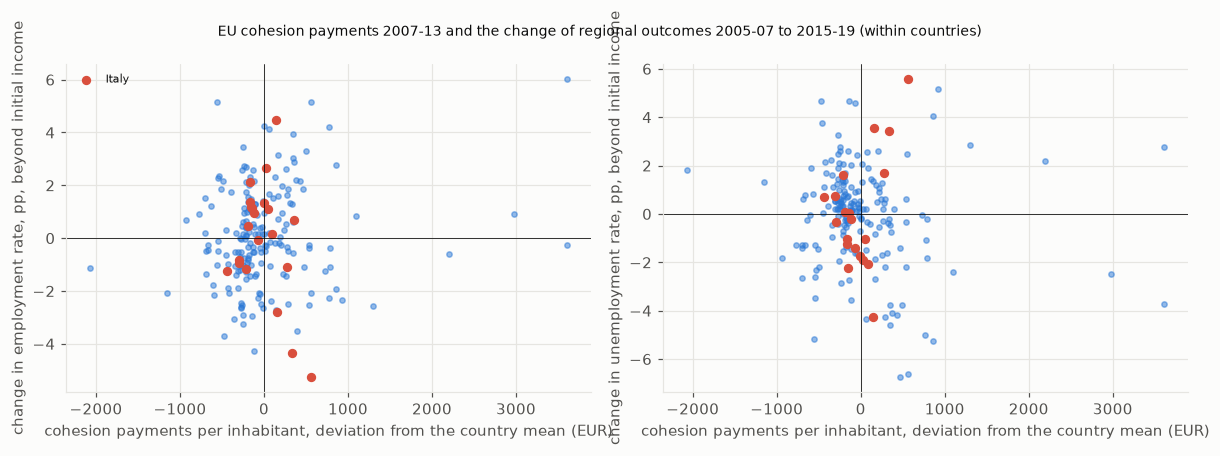

In [2]:
from cifresignificative.analysis import eu_funds as EFM, experiments as ex, regional_corr as rcm, regional_south as rs
fres = ex.run_funds_all()
desc = fres["f1_funds_by_region"].set_index("geo")
print("regions with cohesion payments in the 2007-2013 programme and population/GDP data:", int(desc.funds_cohesion_per_head.notna().sum()), "| countries:", desc.country.nunique())
print("median cohesion payments per inhabitant (EUR, cumulative) and % of GDP by country, top 8:"); display(desc.groupby("country")[["funds_cohesion_per_head", "funds_cohesion_pct_gdp"]].median().sort_values("funds_cohesion_per_head", ascending=False).head(8).round(1).T)
it = desc[desc.country.eq("IT")].sort_values("funds_cohesion_per_head", ascending=False)
print("Italian regions (EUR per inhabitant; % of GDP):"); display(it[["funds_cohesion_per_head", "funds_cohesion_pct_gdp"]].round(1).T)
cols = ["x", "y", "n", "rho", "p", "q_value", "loo_min_abs_rho", "loo_sign_flips"]
print("PRIMARY family (within country, beyond initial income; within-country permutation p; BH over the ten tests):"); display(fres["f2_family"][cols].round(3))
fl = fres["f3_family_filtered"]
print("after spatial filtering of every column:"); display(fl[["x", "y", "n", "rho", "p", "q_value", "rho_filtered", "p_filtered", "q_value_filtered", "same_sign"]].round(3))
print("variants:"); display(fres["f4_variants"][["variant", "x", "y", "n", "rho", "p", "q_value"]].round(3))
print("Italy's slope against the other countries' (p_rank = share of countries at least as far from the others; plain and filtered):"); display(fres["f5_italy_rank"][["x", "y", "n_countries", "slope_diff", "p_rank", "p_rank_filtered"]].round(3))
nl = fres["f6_null"]; print("shuffled null,", len(nl), "shuffles: mean discoveries", round(float(nl.discoveries.mean()), 3), "| shuffles with a discovery", round(float((nl.discoveries > 0).mean()), 3), "| share of p < 0.05", round(float(nl.share_p_below_005.mean()), 3))
fam = fres["f2_family"]; print("discoveries:", int(fam.significant.sum()), "of", len(fam), "| smallest q:", round(float(fam.q_value.min()), 3), "| rho range:", round(float(fam.rho.min()), 3), "to", round(float(fam.rho.max()), 3))
from cifresignificative.sources import eu_payments as epm
reg21 = pd.read_parquet(PROCESSED / "regional_nuts2021.parquet"); Wf = EFM.build_table(reg21, epm.load_period())
fig, axes = plt.subplots(1, 2, figsize=(11, 4)); isit = Wf.index.str[:2] == "IT"
for ax, y, lab in ((axes[0], "employment_rate_20_64", "change in employment rate, pp"), (axes[1], "unemployment_rate", "change in unemployment rate, pp")):
    ax.scatter(Wf.loc[~isit, "funds_cohesion_per_head"], Wf.loc[~isit, y], s=12, color="#2a78d6", alpha=.5); ax.scatter(Wf.loc[isit, "funds_cohesion_per_head"], Wf.loc[isit, y], s=26, color="#d94f3d", label="Italy")
    ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5); ax.set_xlabel("cohesion payments per inhabitant, deviation from the country mean (EUR)"); ax.set_ylabel(lab + ", beyond initial income")
axes[0].legend(fontsize=7); fig.suptitle("EU cohesion payments 2007-13 and the change of regional outcomes 2005-07 to 2015-19 (within countries)", fontsize=9); plt.tight_layout(); plt.show()

In [3]:
nres = ex.run_nuts1_south()
n1c, n2c, n3c = nres["n1_family_comparison"], nres["n2_italy_rank"], nres["n3_de_be_within"]
e = n1c[n1c.x.str.startswith("eqi")]
g = e.groupby(["wave", "income_control"]).agg(tests=("rho_baseline", "size"), survivors_baseline=("significant_baseline", "sum"), survivors_with_de_be=("significant_with_de_be", "sum"), regions_baseline=("n_baseline", "median"), regions_with_de_be=("n_with_de_be", "median"))
print("EQI pairs (composite and three components against the six gaps), baseline against Germany and Belgium added at NUTS1:"); display(g)
print("sign changes of rho:", int((np.sign(e.rho_baseline) != np.sign(e.rho_with_de_be)).sum()), "of", len(e), "| largest change in rho:", round(float((e.rho_baseline - e.rho_with_de_be).abs().max()), 3), "| survivors lost:", int((e.significant_baseline & ~e.significant_with_de_be.fillna(False)).sum()), "| gained:", int((~e.significant_baseline.fillna(False) & e.significant_with_de_be.fillna(False)).sum()))
pr = e[(e.wave == rs.PRIMARY_WAVE) & ~e.income_control & e.x.eq("eqi")][["y", "n_baseline", "rho_baseline", "q_value_baseline", "n_with_de_be", "rho_with_de_be", "q_value_with_de_be"]]
print("2017 wave, composite EQI, plain:"); display(pr.round(3))
ip = n2c[n2c.x.str.startswith("eqi")].pivot_table(index=["x", "y"], columns="geography", values="p_diff")
print("Italy's rank among the countries on the EQI pairs: smallest p_rank baseline", round(float(ip.iloc[:, 0].min()), 3), "| with DE and BE", round(float(ip.iloc[:, 1].min()), 3), "| countries on the EQI pairs", int(n2c[n2c.geography.eq("baseline") & n2c.x.str.startswith("eqi")].n_countries.max()), "->", int(n2c[~n2c.geography.eq("baseline") & n2c.x.str.startswith("eqi")].n_countries.max()))
print("within Germany (16 Laender) and Belgium (3 regions), 2017 wave, beyond income, composite EQI (Belgium has 3 regions: shown, not interpreted):"); display(n3c[n3c.x.eq("eqi")].round(3))

EQI pairs (composite and three components against the six gaps), baseline against Germany and Belgium added at NUTS1:


tests  survivors_baseline  survivors_with_de_be  \
wave income_control                                                    
2010 False              24                  18                    17   
     True               24                  12                    12   
2013 False              24                  21                    20   
     True               24                  16                    14   
2017 False              24                  23                    23   
     True               24                  12                    12   
2021 False              24                  22                    18   
     True               24                  12                    12   

                     regions_baseline  regions_with_de_be  
wave income_control                                        
2010 False                      172.0               191.0  
     True                       167.0               186.0  
2013 False                      177.0               196.0  
     True                       174.5               193.5  
2017 False                      178.5               197.5  
     True                       176.5               195.5  
2021 False                      176.5               195.5  
     True                       176.5               195.5

sign changes of rho: 6 of 192 | largest change in rho: 0.11 | survivors lost: 8 | gained: 0
2017 wave, composite EQI, plain:


,y,n_baseline,rho_baseline,q_value_baseline,n_with_de_be,rho_with_de_be,q_value_with_de_be
4,employment_rate_20_64,181,0.366,0.001,200,0.373,0.001
12,employment_rate_20_64_female,181,0.359,0.001,200,0.355,0.001
20,gdp_per_hour_eur,177,0.187,0.021,196,0.192,0.010
28,gdp_pps_pc_eu27,177,0.306,0.001,196,0.292,0.001
36,hours_per_inhabitant,177,0.307,0.001,196,0.295,0.001
44,unemployment_rate,180,-0.405,0.001,199,-0.426,0.001


Italy's rank among the countries on the EQI pairs: smallest p_rank baseline 0.429 | with DE and BE 0.4 | countries on the EQI pairs 15 -> 16
within Germany (16 Laender) and Belgium (3 regions), 2017 wave, beyond income, composite EQI (Belgium has 3 regions: shown, not interpreted):


,country,x,y,n,rho
0,DE,eqi,gdp_pps_pc_eu27,16,-0.009
1,DE,eqi,gdp_per_hour_eur,16,-0.038
2,DE,eqi,hours_per_inhabitant,16,-0.053
3,DE,eqi,employment_rate_20_64,16,0.085
4,DE,eqi,employment_rate_20_64_female,16,0.071
5,DE,eqi,unemployment_rate,16,-0.406
24,BE,eqi,gdp_pps_pc_eu27,3,-0.500
25,BE,eqi,gdp_per_hour_eur,3,-0.500
26,BE,eqi,hours_per_inhabitant,3,-0.500
27,BE,eqi,employment_rate_20_64,3,1.000


## Takeaways (EU cohesion payments 2007-2013 and the "why the South" family with Germany and Belgium; exploratory and descriptive)
- **The South received much more support per head than the North, but less than the Central and Eastern member states.** Median cumulative cohesion payments of the 2007-2013 programme per inhabitant: Hungary 2,720 euro, Czechia 2,583, Estonia 2,555, Portugal 2,228, Greece 2,207; Italian regions: Calabria 1,543, Sicily 1,260, Puglia 1,216, Campania 1,042, Basilicata 898, Sardinia 597, against 57 for Lombardy. 224 regions of 25 countries have payments and the population and GDP needed.
- **No link between the support and the later change of regional outcomes can be shown.** Within countries and beyond the initial income, 0 of the 10 pre-specified tests (two measures of support times five outcomes) survive false-discovery control (smallest q 0.072; rho between -0.15 and 0.20). The signs are those of a helpful effect but weak: per head of population, rho 0.11 with the change in log GDP per head, 0.12 with the employment rate and -0.15 with the unemployment rate; support as a share of GDP gives 0.02, 0.08 and -0.06. The strongest is hours worked per inhabitant (0.19 and 0.20, q 0.072). After spatial filtering of every column the income and employment links shrink to 0.05 and 0.06 for the per-head measure and hours per inhabitant stays (0.21, q 0.053). The shuffled null gives a discovery in 3% of 100 shuffles.
- **Variants.** Among the pre-2004 member states alone, support per head goes with the employment rate (0.18) and the unemployment rate (-0.18), both q 0.095, still not significant; with a 2005-09 baseline nothing comes close (q 0.105 or more); with all funds including the EAFRD the income link is 0.14 (q 0.134). Without the income control, support is negatively related to the change in GDP per hour (-0.19 and -0.28, q 0.033 and 0.001): that outcome is a change in euro, larger in absolute terms in richer regions, which receive less support, so this mostly restates the initial income and is not interpreted.
- **Italy is not unusual.** Italy's slope is never among the most extreme of the 14-15 countries (smallest p_rank 0.133 plain); after filtering the one pair near the edge is the unemployment rate against support per head (0.071), a single pair among ten.
- **Germany and Belgium change nothing in the EQI result.** With Germany (16 Laender) and Belgium (3 regions) added at NUTS1 the EQI comparisons (2017 wave, plain) rest on about 198 regions instead of about 179; the survivors are 23 of 24 in the 2017 wave in both versions (18 against 17 in 2010, 21 against 20 in 2013, 22 against 18 in 2021; beyond income 12 against 12 in 2010, 2017 and 2021 and 16 against 14 in 2013), 6 of 192 correlations change sign and the largest change in rho is 0.11; the composite EQI against the employment rate is 0.366 without them and 0.373 with them (2017). Italy's smallest rank among the countries on the EQI pairs is 0.43 and then 0.40. Within Germany itself (16 Laender, beyond income) the EQI goes with a lower unemployment rate (-0.41) but not with income or employment (-0.01 and 0.09); Belgium has three regions, too few to read.
- **Limits.** Payments are the Commission's, by calendar year and by NUTS 2013 region mapped to NUTS 2021 (regions that were split, such as Zagreb, Budapest and Warsaw, are left out), not the spending on the ground, and Interreg is not included; funds go to regions for reasons that also drive their outcomes, so the income control cannot make this a causal test; OpenCoesione (national co-financing, 2014-2020) was not used. The NUTS1 outcomes of Germany and Belgium are aggregated from NUTS2, with population weights for rates (an approximation), the structural business statistics do not exist at NUTS1 here so pairs with those predictors are not compared, spatial filtering is not applied to the extension, and the EQI at NUTS1 is a coarser measure than at NUTS2.
